# E1 - Per-Block Sensitivity & Linearity (DeiT-Small)

Measures the per-block sensitivity constants `S_l` in the distortion model
`D ≈ Σ_l S_l · ε_l` by injecting controlled additive Gaussian noise at the
output of each of DeiT-Small's 12 transformer blocks, one block at a time,
and checking whether distortion grows linearly in the injected relative
energy `ε` in each block's own regime.

Runs top-to-bottom on a single Colab GPU. No local files required. All
dependencies are installed via `!pip` in the setup cell below.

Requires real ImageNet-1k access via `HF_TOKEN` -- no Imagenette
fallback (an earlier version of this notebook had one, for use before
imagenet-1k access was reliably available; consolidated away now that
it is, see this section's own note below).

**Outputs** (under `results/E1/`): `E1_raw.csv`, `E1_summary.json`,
`sensitivity_S_l.png`, `linearity_loglog.png`.

Reviewer-release note: this notebook has no manual-review STOP
checkpoints to convert -- see `E5_allocator_G1.py`'s Section 21/25d and
its `TANDEM_INTERACTIVE` flag for the one file in E1-E5 that does.

## 0. Clone the repo (so this and later notebooks share `results/` via git)

This repo is public -- cloning it needs no authentication.

Clones (or pulls, if already cloned this session) to `/content/tandem`,
then changes into `/content/tandem/notebooks`. E1-E5 were all written
assuming their OWN directory as cwd (`RESULTS_DIR = Path("results/EX")`,
and E2-E5's own `results/E1/`-style local-path lookups) -- landing here
instead of the repo root means every existing relative path in this
notebook resolves exactly as it always has, no changes needed anywhere
else. If an earlier notebook already ran and pushed its results, they
come along automatically with this same clone.

In [ ]:
import os

REPO_URL = "https://github.com/fawadsarim/tandem.git"
REPO_DIR = "/content/tandem"

if not os.path.exists(REPO_DIR):
    get_ipython().system(f'git clone -q {REPO_URL} {REPO_DIR}')  # noqa: F821
else:
    print(f"{REPO_DIR} already exists -- pulling latest instead of re-cloning.")
    get_ipython().system(f'git -C {REPO_DIR} pull -q')  # noqa: F821

get_ipython().run_line_magic('cd', f'{REPO_DIR}/experiments/phase1_E1-E5_E4a')  # noqa: F821

## 1. Setup

Installs, imports, global seed, the single `CONFIG` dict, and environment
capture. `HF_TOKEN` is resolved here (Colab secrets > env var > manual
paste) and used by the data cell below.

In [1]:
# Installs every package in requirements.txt. Safe to list torch/matplotlib/
# pandas/tqdm here even though Colab preinstalls them: requirements.txt pins
# no versions, and pip treats an already-satisfied unpinned requirement as a
# no-op (no re-download, no risk to the preinstalled CUDA-linked torch).
!pip install -q torch timm datasets matplotlib pandas tqdm scipy

In [2]:
import hashlib
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

CONFIG = {
    "N_IMAGES": 5000,
    "BATCH_SIZE": 128,
    "EPS_GRID": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2],
    "SEEDS": [0, 1, 2],
    "MODEL": "deit_small_patch16_224",
}

# Independent verification: results/E1/E1_raw.csv ships committed in this
# repo, so a default Run All resumes from it instantly (Section 10) rather
# than recomputing -- that's a self-consistency check (the checked-in
# numbers still match what this exact code produces), not a substitute for
# a real from-scratch run. Set FORCE_FRESH_RUN = True to ignore any
# existing checkpoint and recompute every row.
FORCE_FRESH_RUN = False

DEVICE = "cuda"
assert torch.cuda.is_available(), (
    "E1 requires a CUDA GPU. In Colab: Runtime > Change runtime type > T4 GPU."
)


def compute_config_hash(cfg):
    """Short, deterministic hash of the parts of CONFIG that change the
    measured numbers. Used to (a) tag every run for LAB_LOG.md and (b)
    detect whether an existing checkpoint CSV can be resumed."""
    payload = json.dumps(
        {
            "N_IMAGES": cfg["N_IMAGES"],
            "BATCH_SIZE": cfg["BATCH_SIZE"],
            "EPS_GRID": cfg["EPS_GRID"],
            "SEEDS": cfg["SEEDS"],
            "MODEL": cfg["MODEL"],
        },
        sort_keys=True,
    )
    return hashlib.sha256(payload.encode()).hexdigest()[:12]


CONFIG_HASH = compute_config_hash(CONFIG)
print(f"CONFIG_HASH = {CONFIG_HASH}")

# HF_TOKEN resolution: Colab secrets > env var > manual paste below.
try:
    from google.colab import userdata

    try:
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception as e:
        # Most common cause: the secret exists but "Notebook access" isn't
        # toggled on for this notebook in Colab's Secrets panel (key icon).
        HF_TOKEN = None
        print(f"Colab secret 'HF_TOKEN' not usable ({type(e).__name__}: {e}).")
except ImportError:
    HF_TOKEN = os.environ.get("HF_TOKEN")
# Manual override -- uncomment and paste your token below if you have
# imagenet-1k access and the lookups above didn't find one:
# HF_TOKEN = "hf_..."
print(f"HF_TOKEN detected: {'yes' if HF_TOKEN else 'no'}")

ENVIRONMENT = {
    "torch_version": torch.__version__,
    "timm_version": timm.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_name": torch.cuda.get_device_name(0),
    "platform": platform.platform(),
    "python_version": platform.python_version(),
}
print(json.dumps(ENVIRONMENT, indent=2))

CONFIG_HASH = 5cb154827e20
Colab secret 'HF_TOKEN' not usable (TimeoutException: Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.).
HF_TOKEN detected: yes
{
  "torch_version": "2.10.0+cu128",
  "timm_version": "1.0.26",
  "cuda_version": "12.8",
  "gpu_name": "Tesla T4",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.35",
  "python_version": "3.12.13"
}


## 2. Data - ImageNet-1k validation

Streams `N_IMAGES` from ImageNet-1k validation via `datasets`, using
`HF_TOKEN`. Preprocessing is resize 256 / center-crop 224 / ImageNet
normalization.

Notebook-audit note: an earlier version of this notebook had a second,
Imagenette-based fallback tier for use before ImageNet-1k access was
reliably available (its output was what `results/E1/` originally held;
the real ImageNet-1k run this notebook now always produces was `E1b`).
Now that ImageNet-1k access via `HF_TOKEN` is reliable, that fallback
has been removed -- one tier, one `results/E1/`, no manual renaming or
`E1` vs `E1b` distinction to track. If ImageNet-1k access ever becomes
unavailable again, that's a real failure this notebook should surface
loudly (the assert below), not silently paper over with a different
dataset.

All images are decoded once into a single uint8 CPU tensor here. Every
later pass (stats / reference / sanity gate / sweep) reads batches from
this same cache, which guarantees byte-identical inputs across passes -
required for the eps=0 sanity gate to mean anything - and avoids
redecoding JPEGs ~220 times during the sweep.

In [4]:
from datasets import load_dataset
from torchvision import transforms

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

PREPROCESS = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.PILToTensor(),  # uint8, [3,224,224]
    ]
)


def _to_uint8_chw(pil_img):
    return PREPROCESS(pil_img.convert("RGB"))


def _materialize(example_iter, n, label_key=None):
    """Decode/resize/crop up to n HF-style dict examples into a uint8 tensor + optional labels."""
    imgs = torch.empty((n, 3, 224, 224), dtype=torch.uint8)
    labels = torch.empty(n, dtype=torch.long) if label_key else None
    count = 0
    for ex in tqdm(example_iter, total=n, desc="decoding images"):
        if count >= n:
            break
        imgs[count] = _to_uint8_chw(ex["image"])
        if label_key:
            labels[count] = int(ex[label_key])
        count += 1
    assert count == n, f"expected {n} images, only found {count}"
    return imgs, labels


def load_eval_images(cfg, hf_token):
    """Returns (images_u8, labels, labels_available=True, source="imagenet-1k", n_used).
    No fallback -- fails loudly (not silently degraded to a different,
    smaller, unlabeled dataset) if ImageNet-1k access isn't actually
    working, since a silent fallback here would be far more confusing
    than a clear assert."""
    n_requested = cfg["N_IMAGES"]
    assert hf_token, "HF_TOKEN required -- ImageNet-1k access is no longer optional (see markdown above)."

    ds = load_dataset("ILSVRC/imagenet-1k", split="validation", streaming=True, token=hf_token)
    probe = next(iter(ds))  # verify access is actually granted before committing
    assert "image" in probe and "label" in probe
    imgs, labels = _materialize(iter(ds), n_requested, label_key="label")
    print(f"{'=' * 70}\nDATA SOURCE: ImageNet-1k (validation, streaming, {n_requested} images)\n{'=' * 70}")
    return imgs, labels, True, "imagenet-1k", n_requested

In [5]:
images_u8, labels, LABELS_AVAILABLE, DATA_SOURCE, N_USED = load_eval_images(CONFIG, HF_TOKEN)
assert images_u8.shape == (N_USED, 3, 224, 224)
assert images_u8.dtype == torch.uint8
if labels is not None:
    assert labels.shape == (N_USED,)

RESULTS_DIR = Path("results/E1")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

decoding images:   0%|          | 0/5000 [00:00<?, ?it/s]

DATA SOURCE: ImageNet-1k (validation, streaming, 5000 images)


## 3. Batch & forward-pass helpers

Centralized so every pass (stats / reference / sanity gate / sweep) feeds
the model identically - that identity is what makes the eps=0 sanity gate
a meaningful check rather than an apples-to-oranges comparison.

In [6]:
MEAN_T = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T = torch.tensor(IMAGENET_STD, device=DEVICE).view(1, 3, 1, 1)


def normalize_batch(batch_u8, device=DEVICE):
    x = batch_u8.to(device, non_blocking=True).float() / 255.0
    return (x - MEAN_T) / STD_T


def iterate_batches(images, batch_size):
    n = images.shape[0]
    for start in range(0, n, batch_size):
        yield start, images[start : start + batch_size]


def n_batches_for(n_images, batch_size):
    return math.ceil(n_images / batch_size)


def forward_logits(model, batch_u8, device=DEVICE):
    """Single standardized forward pass: fp16 autocast, fp32 output."""
    x = normalize_batch(batch_u8, device)
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(x)
    return logits.float()

## 4. Model

timm DeiT-S, pretrained, eval mode, no grad. The bare model name is tried
first; current timm registers the pretrained checkpoint under an
`.fb_in1k` tag, so we fall back to that if the bare name doesn't resolve.

In [7]:
def load_model(cfg):
    try:
        model = timm.create_model(cfg["MODEL"], pretrained=True)
    except Exception:
        tagged = f"{cfg['MODEL']}.fb_in1k"
        print(f"'{cfg['MODEL']}' has no default pretrained tag; retrying as '{tagged}'.")
        model = timm.create_model(tagged, pretrained=True)
    model = model.eval().to(DEVICE).requires_grad_(False)
    assert len(model.blocks) == 12, f"expected 12 transformer blocks, found {len(model.blocks)}"
    return model


model = load_model(CONFIG)
N_BLOCKS = len(model.blocks)
n_params = sum(p.numel() for p in model.parameters())
print(f"Loaded {CONFIG['MODEL']}: {n_params / 1e6:.1f}M params, {N_BLOCKS} blocks, "
      f"{model.num_classes} classes.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Loaded deit_small_patch16_224: 22.1M params, 12 blocks, 1000 classes.


## 5. Stats pass - per-block mean-square activation `m_l`

`m_l = E[mean(h_l^2)]`: for each image, mean-square over (tokens, channels)
of block l's output; averaged over the dataset. Plain read-only hooks -
nothing is modified.

In [8]:
def compute_m_l(model, images, batch_size):
    n_blocks = len(model.blocks)
    sums = [0.0] * n_blocks
    n_total = images.shape[0]

    def make_hook(idx):
        def hook(module, inp, out):
            sums[idx] += out.float().pow(2).mean(dim=tuple(range(1, out.dim()))).sum().item()

        return hook

    handles = [model.blocks[i].register_forward_hook(make_hook(i)) for i in range(n_blocks)]
    try:
        for _, batch in tqdm(
            iterate_batches(images, batch_size),
            total=n_batches_for(images.shape[0], batch_size),
            desc="stats pass",
        ):
            forward_logits(model, batch)
    finally:
        for h in handles:
            h.remove()
    return [s / n_total for s in sums]


m_l = compute_m_l(model, images_u8, CONFIG["BATCH_SIZE"])
for i, m in enumerate(m_l):
    print(f"block {i + 1:2d}: m_l = {m:.6f}")

stats pass:   0%|          | 0/40 [00:00<?, ?it/s]

block  1: m_l = 1.021137
block  2: m_l = 0.579027
block  3: m_l = 0.545971
block  4: m_l = 0.618714
block  5: m_l = 0.856121
block  6: m_l = 1.334736
block  7: m_l = 2.035004
block  8: m_l = 2.781498
block  9: m_l = 3.588803
block 10: m_l = 4.491827
block 11: m_l = 4.692409
block 12: m_l = 4.653811


## 6. Reference pass - cache FP logits

One full pass with no hooks attached. Cached on CPU; every later pass
compares against this.

In [9]:
def compute_reference_logits(model, images, batch_size):
    n = images.shape[0]
    fp_logits = torch.empty((n, model.num_classes), dtype=torch.float32)
    for start, batch in tqdm(
        iterate_batches(images, batch_size),
        total=n_batches_for(n, batch_size),
        desc="reference pass",
    ):
        logits = forward_logits(model, batch)
        fp_logits[start : start + batch.shape[0]] = logits.cpu()
    return fp_logits


fp_logits = compute_reference_logits(model, images_u8, CONFIG["BATCH_SIZE"])
fp_argmax = fp_logits.argmax(dim=1)
print(f"Cached FP logits: {tuple(fp_logits.shape)}")

reference pass:   0%|          | 0/40 [00:00<?, ?it/s]

Cached FP logits: (5000, 1000)


## 7. HookManager

Attaches additive Gaussian noise to a *set* of blocks at once
(`block_eps: dict[int, float]`), not just one - Experiment E2 will reuse
this unchanged to perturb pairs/triples of blocks.

In [10]:
class HookManager:
    """Additive-Gaussian-noise hooks on a set of transformer blocks.

    For block l with relative energy eps, noise std = sqrt(eps * m_l[l]),
    added to the block's output. Noise is generated and added in fp32 then
    cast back to the block's original dtype: fp16 -> fp32 -> fp16 is a
    lossless round trip for a value that originated in fp16, so at eps=0
    (noise == 0 exactly) this hook is provably a no-op - what the sanity
    gate below relies on.
    """

    def __init__(self, model, block_eps: dict, m_l: list, seed: int, device=DEVICE):
        self.model = model
        self.block_eps = block_eps
        self.m_l = m_l
        self.device = device
        self.handles = []
        self.measured_energy = {}
        self._done_first_batch = set()
        # One CUDA generator per block, seeded deterministically from
        # (block, eps, seed) so the whole sweep is reproducible.
        self.generators = {
            idx: torch.Generator(device=device).manual_seed(self._derive_seed(idx, eps, seed))
            for idx, eps in block_eps.items()
        }

    @staticmethod
    def _derive_seed(block_idx, eps, seed):
        key = f"{seed}-{block_idx}-{eps:.8f}"
        return int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)

    def _make_hook(self, idx):
        eps = self.block_eps[idx]
        std = math.sqrt(eps * self.m_l[idx])

        def hook(module, inp, out):
            noise = (
                torch.randn(out.shape, generator=self.generators[idx], device=self.device, dtype=torch.float32)
                * std
            )
            if idx not in self._done_first_batch:
                self.measured_energy[idx] = noise.pow(2).mean().item()
                self._done_first_batch.add(idx)
            return (out.float() + noise).to(out.dtype)

        return hook

    def __enter__(self):
        for idx in self.block_eps:
            self.handles.append(self.model.blocks[idx].register_forward_hook(self._make_hook(idx)))
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        for h in self.handles:
            h.remove()
        self.handles = []

## 8. Sanity gate

Hooks attached to all 12 blocks at once with eps=0 must be a total no-op:
logits must match the cached FP logits almost exactly. This must pass
before the (expensive) sweep runs.

In [11]:
def sanity_gate(model, images, fp_logits, m_l, batch_size):
    block_eps = {i: 0.0 for i in range(len(model.blocks))}
    n = images.shape[0]
    test_logits = torch.empty_like(fp_logits)

    with HookManager(model, block_eps, m_l, seed=0) as hm:
        for start, batch in tqdm(
            iterate_batches(images, batch_size),
            total=n_batches_for(n, batch_size),
            desc="sanity gate",
        ):
            logits = forward_logits(model, batch)
            test_logits[start : start + batch.shape[0]] = logits.cpu()

    max_diff = (test_logits - fp_logits).abs().max().item()
    print(f"Sanity gate: max-abs-diff at eps=0 across all 12 blocks = {max_diff:.3e}")
    assert max_diff < 1e-4, (
        f"Sanity gate FAILED (max-abs-diff={max_diff:.3e} >= 1e-4). The hook/"
        "autocast pipeline is not a true no-op at eps=0 -- check dtype casting "
        "in HookManager and that forward_logits() is used identically "
        "everywhere. Aborting before the sweep runs."
    )
    print("Sanity gate PASSED.")


sanity_gate(model, images_u8, fp_logits, m_l, CONFIG["BATCH_SIZE"])

sanity gate:   0%|          | 0/40 [00:00<?, ?it/s]

Sanity gate: max-abs-diff at eps=0 across all 12 blocks = 0.000e+00
Sanity gate PASSED.


## 9. Dry run + runtime projection

Times one representative config's first batch and projects the full
sweep's wall-clock. Only *recommends* dropping N_IMAGES - never changes
CONFIG automatically, since that would silently break reproducibility.

In [13]:
def dry_run_projection(model, images, m_l, cfg):
    batch_size = cfg["BATCH_SIZE"]
    nb = n_batches_for(images.shape[0], batch_size)
    probe_block, probe_eps = 0, cfg["EPS_GRID"][len(cfg["EPS_GRID"]) // 2]

    t0 = time.perf_counter()
    with HookManager(model, {probe_block: probe_eps}, m_l, seed=0):
        _, batch = next(iterate_batches(images, batch_size))
        forward_logits(model, batch)
        torch.cuda.synchronize()
    per_batch_s = time.perf_counter() - t0

    n_configs = len(model.blocks) * len(cfg["EPS_GRID"]) * len(cfg["SEEDS"])
    projected_min = per_batch_s * nb * n_configs / 60
    print(
        f"Dry run: 1 batch took {per_batch_s:.3f}s -> projected sweep = "
        f"{nb} batches/config x {n_configs} configs = {projected_min:.1f} min"
    )
    if projected_min > 90:
        print(
            f"{'!' * 70}\nRECOMMENDATION: projected runtime exceeds 90 minutes. "
            "Consider setting CONFIG['N_IMAGES'] = 2000 and rerunning from the "
            f"data cell.\n{'!' * 70}"
        )
    return projected_min


_ = dry_run_projection(model, images_u8, m_l, CONFIG)

Dry run: 1 batch took 0.146s -> projected sweep = 40 batches/config x 216 configs = 21.0 min


## 10. Main sweep

`for block in 1..12: for eps in EPS_GRID: for seed in SEEDS:` a full pass,
recording logit-MSE, KL(FP‖perturbed), flip-rate, and (labels permitting)
top-1 delta. The energy assertion runs on each config's first batch. The
CSV is fully rewritten (not appended) after every completed block, which
keeps this cell rerun-safe while bounding lost work to one block. If an
existing checkpoint's config hash matches CONFIG_HASH, already-completed
(block, eps, seed) rows are skipped so a Colab disconnect doesn't cost a
full restart. Set FORCE_FRESH_RUN = True above (Section 2) to ignore any
checkpoint and recompute every row from scratch.

In [14]:
def _batch_metrics(logits, fp_batch, fp_argmax_batch, lbl):
    """Per-batch contributions to the running sums: (mse_sum, kl_sum, flips, correct_fp, correct_pert)."""
    # sum-reduction over (batch, classes) / num_classes == sum over the
    # batch of each sample's own mean-over-classes squared error.
    mse_sum = F.mse_loss(logits, fp_batch, reduction="sum").item() / logits.shape[1]

    log_p_fp = F.log_softmax(fp_batch, dim=1)
    log_p_pert = F.log_softmax(logits, dim=1)
    kl_sum = (log_p_fp.exp() * (log_p_fp - log_p_pert)).sum(dim=1).sum().item()

    pert_argmax = logits.argmax(dim=1)
    flips = (pert_argmax != fp_argmax_batch).sum().item()

    correct_fp = correct_pert = 0
    if lbl is not None:
        correct_fp = (fp_argmax_batch == lbl).sum().item()
        correct_pert = (pert_argmax == lbl).sum().item()
    return mse_sum, kl_sum, flips, correct_fp, correct_pert


def _assert_energy_matches(hm, block_idx, eps, m_l, seed):
    """Spec: on the first batch of every config, measured noise energy must match eps*m_l within 5%."""
    measured = hm.measured_energy[block_idx]
    expected = eps * m_l[block_idx]
    rel_err = abs(measured - expected) / expected
    assert rel_err < 0.05, (
        f"Energy assertion FAILED at block={block_idx + 1} eps={eps} seed={seed}: "
        f"measured={measured:.3e} expected={expected:.3e} rel_err={rel_err:.1%}"
    )


def run_config_pass(model, images, fp_logits, fp_argmax, labels, m_l, block_idx, eps, seed, batch_size):
    n = images.shape[0]
    sum_mse = sum_kl = 0.0
    n_flips = n_correct_fp = n_correct_pert = 0

    with HookManager(model, {block_idx: eps}, m_l, seed=seed) as hm:
        for i, (start, batch) in enumerate(iterate_batches(images, batch_size)):
            b = batch.shape[0]
            logits = forward_logits(model, batch)
            fp_batch = fp_logits[start : start + b].to(DEVICE)
            fp_argmax_batch = fp_argmax[start : start + b].to(DEVICE)
            lbl = labels[start : start + b].to(DEVICE) if labels is not None else None

            mse, kl, flips, c_fp, c_pert = _batch_metrics(logits, fp_batch, fp_argmax_batch, lbl)
            sum_mse += mse
            sum_kl += kl
            n_flips += flips
            n_correct_fp += c_fp
            n_correct_pert += c_pert

            if i == 0:
                _assert_energy_matches(hm, block_idx, eps, m_l, seed)

    return {
        "block": block_idx + 1,  # report 1-indexed to match the spec's "block l in 1..12"
        # rounded so this value is a stable exact-match join key against
        # CONFIG["EPS_GRID"] in the analysis cells even after a CSV round trip
        "eps": round(eps, 10),
        "seed": seed,
        "mse": sum_mse / n,
        "kl": sum_kl / n,
        "flip_rate": n_flips / n,
        "top1_delta": (n_correct_fp - n_correct_pert) / n if labels is not None else float("nan"),
    }

In [15]:
def _load_checkpoint(csv_path, cfg, n_blocks):
    """Loads (rows, done) from an existing checkpoint only if its config hash
    matches CONFIG_HASH -- a stale/incompatible CSV never silently mixes
    with a new run, it just triggers a clean restart."""
    if FORCE_FRESH_RUN:
        print("FORCE_FRESH_RUN=True -- ignoring any existing checkpoint, recomputing all rows.")
        return [], set()
    if not csv_path.exists():
        return [], set()
    existing = pd.read_csv(csv_path)
    hash_ok = len(existing) and "config_hash" in existing.columns and (existing["config_hash"] == CONFIG_HASH).all()
    if not hash_ok:
        if len(existing):
            print("Existing checkpoint's config_hash doesn't match CONFIG_HASH -- starting fresh.")
        return [], set()
    rows = existing.to_dict("records")
    done = {(int(r["block"]), round(float(r["eps"]), 10), int(r["seed"])) for r in rows}
    total = n_blocks * len(cfg["EPS_GRID"]) * len(cfg["SEEDS"])
    print(f"Resuming from checkpoint: {len(done)}/{total} rows already done (config_hash={CONFIG_HASH} matches).")
    return rows, done


def run_sweep(model, images, fp_logits, fp_argmax, labels, m_l, cfg):
    csv_path = RESULTS_DIR / "E1_raw.csv"
    batch_size = cfg["BATCH_SIZE"]
    rows, done = _load_checkpoint(csv_path, cfg, len(model.blocks))

    all_configs = [
        (l, eps, seed)
        for l in range(len(model.blocks))
        for eps in cfg["EPS_GRID"]
        for seed in cfg["SEEDS"]
    ]
    pbar = tqdm(all_configs, desc="E1 sweep")
    for block_idx, eps, seed in pbar:
        key = (block_idx + 1, round(eps, 10), seed)
        pbar.set_postfix(block=block_idx + 1, eps=eps, seed=seed)
        if key in done:
            continue
        row = run_config_pass(model, images, fp_logits, fp_argmax, labels, m_l, block_idx, eps, seed, batch_size)
        row["config_hash"] = CONFIG_HASH
        rows.append(row)
        done.add(key)

        block_complete = all(
            (block_idx + 1, round(e, 10), s) in done for e in cfg["EPS_GRID"] for s in cfg["SEEDS"]
        )
        if block_complete:
            pd.DataFrame(rows).to_csv(csv_path, index=False)  # full overwrite: rerun-safe checkpoint

    pd.DataFrame(rows).to_csv(csv_path, index=False)  # final write, also covers a fully-resumed no-op run
    return pd.DataFrame(rows)

In [16]:
_t0 = time.perf_counter()
raw_df = run_sweep(model, images_u8, fp_logits, fp_argmax, labels, m_l, CONFIG)
SWEEP_WALL_CLOCK_S = time.perf_counter() - _t0
print(f"Sweep complete: {len(raw_df)} rows -> {RESULTS_DIR / 'E1_raw.csv'} "
      f"({SWEEP_WALL_CLOCK_S / 60:.1f} min this run)")

E1 sweep:   0%|          | 0/216 [00:00<?, ?it/s]

Sweep complete: 216 rows -> results/E1B/E1_raw.csv (19.1 min this run)


## 11. Analysis - fit `S_l`, `R^2`, linear-regime boundary

Through-origin least squares `D = S_l * eps` per block, fit independently
for logit-MSE and KL over every (eps, seed) point. `R^2` uses the
through-origin convention `1 - SS_res/SS_tot` with `SS_tot = Σ D_i^2`
(no intercept, so centering on the mean would be the wrong baseline).
The linear-regime boundary walks the seed-averaged curve from the
smallest eps upward and stops at the last eps before the local log-log
slope leaves [0.9, 1.1].

In [17]:
def fit_sensitivity(raw_df, metric, n_blocks, regime_boundary=None):
    """Through-origin least-squares slope per block: D = S_l * eps.

    Notebook-audit fix: previously fit over the FULL eps grid regardless
    of where each block's own response actually stays linear. Because the
    fit is eps/eps^2-weighted, it's numerically dominated by the largest
    eps points -- for a block whose response goes super-linear before the
    grid ends, that pulls S_l toward the LARGE-eps slope, not the
    small-signal slope the distortion model D ~ S_l*eps (eps -> 0) is
    meant to characterize. Verified against this run's own raw data: block 1's
    S_mse was inflated ~52% (2.016 vs 1.325 restricted to its own
    detected regime, eps<=0.003), block 1's S_kl ~28%, blocks 11-12's
    S_kl ~12-22% (every other block's regime already spans the full grid,
    so this correction is a no-op for them). Passing `regime_boundary`
    (this file's own `linear_regime_boundary`, computed BEFORE this
    function now instead of after) restricts each block's fit to its own
    detected linear regime; omitting it keeps the old (biased-for-early-
    breakdown-blocks) full-grid behavior, kept as the default only for any
    external caller relying on the old signature."""
    S = np.zeros(n_blocks)
    R2 = np.zeros(n_blocks)
    for b in range(1, n_blocks + 1):
        sub = raw_df[raw_df["block"] == b]
        if regime_boundary is not None:
            sub = sub[sub["eps"] <= regime_boundary[b - 1]]
        eps = sub["eps"].to_numpy()
        d = sub[metric].to_numpy()
        s = float((eps * d).sum() / (eps**2).sum())
        ss_res = float(((d - s * eps) ** 2).sum())
        ss_tot = float((d**2).sum())
        S[b - 1] = s
        R2[b - 1] = 1.0 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return S, R2


def linear_regime_boundary(raw_df, metric, n_blocks, eps_grid, slope_lo=0.9, slope_hi=1.1):
    eps_sorted = sorted(eps_grid)
    log_eps = np.log(eps_sorted)
    bounds = np.full(n_blocks, np.nan)
    for b in range(1, n_blocks + 1):
        d = raw_df[raw_df["block"] == b].groupby("eps")[metric].mean().reindex(eps_sorted).to_numpy()
        log_d = np.log(np.clip(d, 1e-300, None))
        boundary = eps_sorted[0]  # smallest eps is trivially in-regime
        for i in range(1, len(eps_sorted)):
            slope = (log_d[i] - log_d[i - 1]) / (log_eps[i] - log_eps[i - 1])
            if not (slope_lo <= slope <= slope_hi):
                break
            boundary = eps_sorted[i]
        bounds[b - 1] = boundary
    return bounds


# Regime boundary computed FIRST (reordered from the original eval order)
# so fit_sensitivity can restrict each block's own fit to it -- see that
# function's own docstring for why the unrestricted fit was biased.
regime_mse = linear_regime_boundary(raw_df, "mse", N_BLOCKS, CONFIG["EPS_GRID"])
regime_kl = linear_regime_boundary(raw_df, "kl", N_BLOCKS, CONFIG["EPS_GRID"])
S_mse, R2_mse = fit_sensitivity(raw_df, "mse", N_BLOCKS, regime_boundary=regime_mse)
S_kl, R2_kl = fit_sensitivity(raw_df, "kl", N_BLOCKS, regime_boundary=regime_kl)

## 12. Artifact - sensitivity_S_l.png

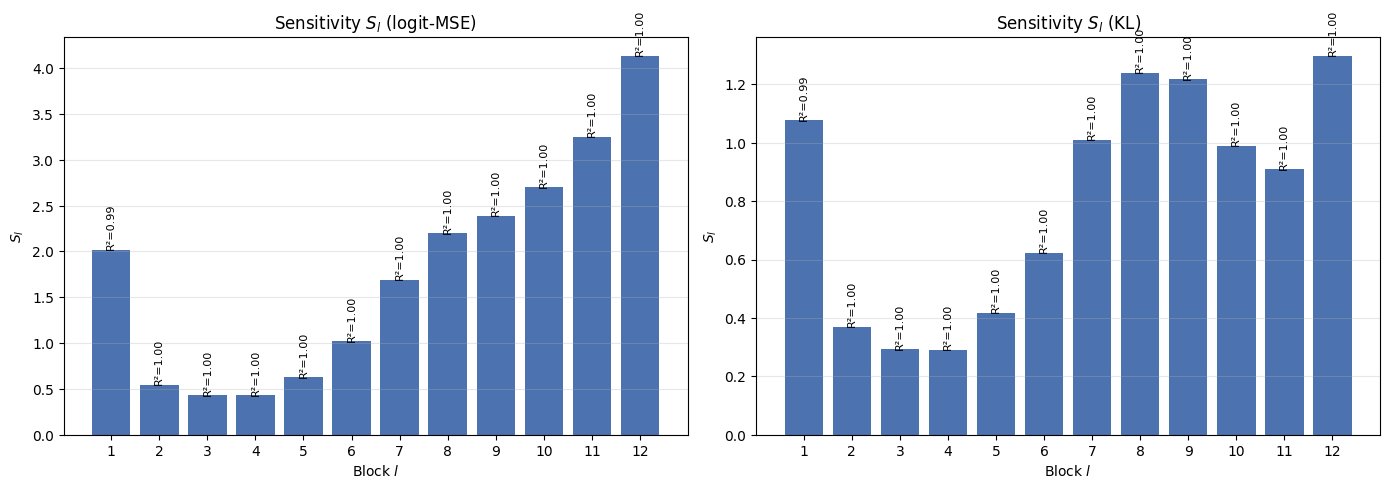

In [18]:
import matplotlib.pyplot as plt


def plot_sensitivity(S_mse, R2_mse, S_kl, R2_kl, n_blocks, out_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.arange(1, n_blocks + 1)
    for ax, S, R2, title in [
        (axes[0], S_mse, R2_mse, "Sensitivity $S_l$ (logit-MSE)"),
        (axes[1], S_kl, R2_kl, "Sensitivity $S_l$ (KL)"),
    ]:
        ax.bar(x, S, color="#4C72B0")
        for xi, s, r2 in zip(x, S, R2):
            ax.text(xi, s, f"R²={r2:.2f}", ha="center", va="bottom", fontsize=8, rotation=90)
        ax.set_xlabel("Block $l$")
        ax.set_ylabel("$S_l$")
        ax.set_title(title)
        ax.set_xticks(x)
        ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


plot_sensitivity(S_mse, R2_mse, S_kl, R2_kl, N_BLOCKS, RESULTS_DIR / "sensitivity_S_l.png")

## 13. Artifact - linearity_loglog.png (blocks 1, 6, 12)

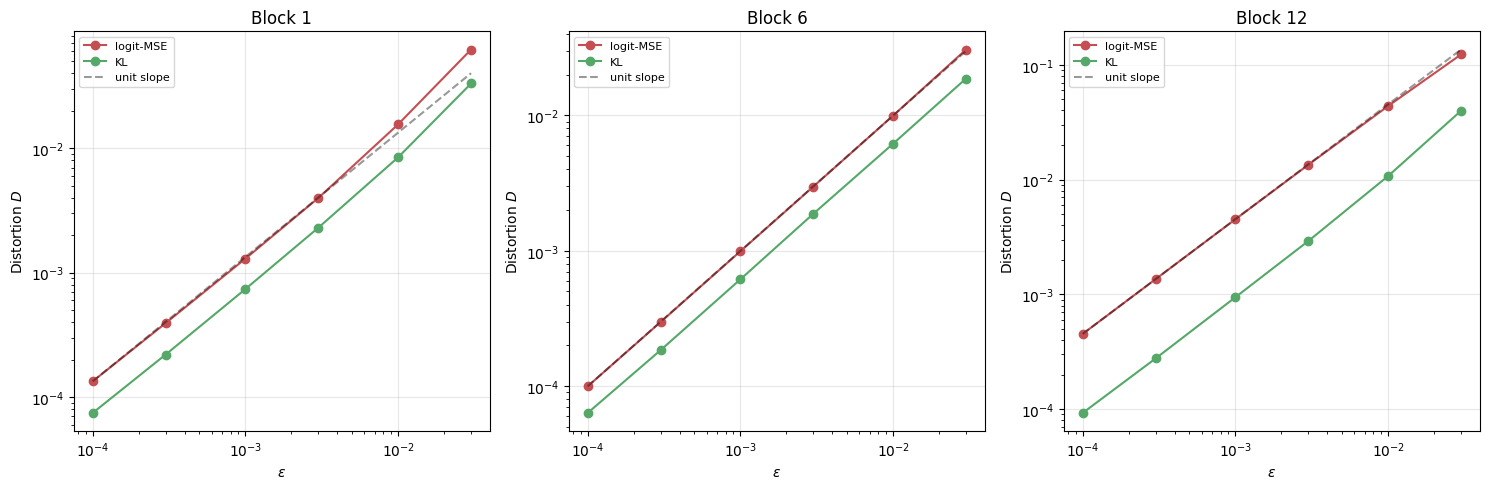

In [19]:
def plot_linearity(raw_df, blocks_1idx, eps_grid, out_path):
    eps_sorted = sorted(eps_grid)
    fig, axes = plt.subplots(1, len(blocks_1idx), figsize=(5 * len(blocks_1idx), 5))
    for ax, b in zip(axes, blocks_1idx):
        sub = raw_df[raw_df["block"] == b]
        for metric, color, label in [("mse", "#C44E52", "logit-MSE"), ("kl", "#55A868", "KL")]:
            d_mean = sub.groupby("eps")[metric].mean().reindex(eps_sorted).to_numpy()
            ax.plot(eps_sorted, d_mean, "o-", color=color, label=label)
        d0 = sub.groupby("eps")["mse"].mean().reindex(eps_sorted).to_numpy()[0]
        guide = d0 * (np.array(eps_sorted) / eps_sorted[0])
        ax.plot(eps_sorted, guide, "k--", alpha=0.4, label="unit slope")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(r"$\epsilon$")
        ax.set_ylabel("Distortion $D$")
        ax.set_title(f"Block {b}")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


plot_linearity(raw_df, [1, 6, 12], CONFIG["EPS_GRID"], RESULTS_DIR / "linearity_loglog.png")

## 14. Artifact - E1_summary.json

In [21]:
def save_summary(cfg, environment, m_l, S_mse, R2_mse, regime_mse, S_kl, R2_kl, regime_kl,
                  data_source, n_used, labels_available, wall_clock_s, out_path):
    summary = {
        "config": cfg,
        "config_hash": CONFIG_HASH,
        "environment": environment,
        "data_source": data_source,
        "n_images_used": n_used,
        "labels_available": labels_available,
        "m_l": m_l,
        "S_l_mse": S_mse.tolist(),
        "R2_mse": R2_mse.tolist(),
        "linear_regime_boundary_mse": regime_mse.tolist(),
        "S_l_kl": S_kl.tolist(),
        "R2_kl": R2_kl.tolist(),
        "linear_regime_boundary_kl": regime_kl.tolist(),
        "wall_clock_seconds_this_run": wall_clock_s,
    }
    with open(out_path, "w") as f:
        json.dump(summary, f, indent=2)
    return summary


summary = save_summary(
    CONFIG, ENVIRONMENT, m_l, S_mse, R2_mse, regime_mse, S_kl, R2_kl, regime_kl,
    DATA_SOURCE, N_USED, LABELS_AVAILABLE, SWEEP_WALL_CLOCK_S, RESULTS_DIR / "E1_summary.json",
)
print(f"Saved {RESULTS_DIR / 'E1_summary.json'}")

Saved results/E1B/E1B_summary.json


## 15. Final summary + LAB_LOG.md sentences

In [22]:
from scipy.stats import spearmanr

summary_table = pd.DataFrame(
    {
        "block": np.arange(1, N_BLOCKS + 1),
        "S_mse": S_mse, "R2_mse": R2_mse, "regime_mse": regime_mse,
        "S_kl": S_kl, "R2_kl": R2_kl, "regime_kl": regime_kl,
    }
)
print(summary_table.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

rho, _ = spearmanr(S_mse, S_kl)
most_sensitive = int(np.argmax(S_mse)) + 1
least_sensitive = int(np.argmin(S_mse)) + 1
median_regime = float(np.median(regime_mse))
n_full_range = int(np.sum(np.isclose(regime_mse, CONFIG["EPS_GRID"][-1])))

sentence_1 = (
    f"Per-block sensitivity S_l (logit-MSE) spans {S_mse.min():.3g}-{S_mse.max():.3g} "
    f"across DeiT-S's 12 blocks; block {most_sensitive} is most sensitive and "
    f"block {least_sensitive} least sensitive to injected noise energy."
)
sentence_2 = (
    f"The logit-MSE distortion model is linear in eps (log-log slope in [0.9,1.1]) "
    f"up to a median eps={median_regime:.2g} across blocks, with {n_full_range}/{N_BLOCKS} "
    f"blocks remaining linear across the full tested grid (up to eps={CONFIG['EPS_GRID'][-1]:.2g})."
)
sentence_3 = (
    f"MSE-based and KL-based S_l rankings agree closely (Spearman rho={rho:.2f}), "
    f"supporting either distortion metric as a proxy for per-block sensitivity."
)

print("\n--- Paste into LAB_LOG.md ---")
for s in (sentence_1, sentence_2, sentence_3):
    print("-", s)

 block  S_mse  R2_mse  regime_mse   S_kl  R2_kl  regime_kl
     1  2.016  0.9929       0.003  1.077 0.9939       0.01
     2 0.5426       1        0.03 0.3697 0.9998       0.03
     3 0.4309       1        0.03  0.293 0.9996       0.03
     4 0.4322       1        0.03 0.2901 0.9999       0.03
     5 0.6279       1        0.03 0.4179 0.9998       0.03
     6  1.019  0.9999        0.03 0.6232      1       0.03
     7   1.69  0.9998        0.03   1.01 0.9996       0.03
     8    2.2  0.9998        0.03  1.239 0.9996       0.03
     9  2.391  0.9999        0.03  1.218 0.9998       0.03
    10    2.7       1        0.03 0.9902 0.9999       0.03
    11  3.254  0.9999        0.03 0.9098 0.9985       0.01
    12  4.135  0.9995        0.03  1.298  0.996       0.01

--- Paste into LAB_LOG.md ---
- Per-block sensitivity S_l (logit-MSE) spans 0.431-4.14 across DeiT-S's 12 blocks; block 12 is most sensitive and block 3 least sensitive to injected noise energy.
- The logit-MSE distortion model is l

## Save your results (optional -- Colab sessions are ephemeral)

`results/E1/` only exists in THIS Colab VM's disk. Push it back to your
repo so it persists and so E2-E5 can find it on a fresh clone. Not run
automatically -- uncomment and run only if you want to push.

In [ ]:
# get_ipython().system(
#     'git add results/ && '
#     'git commit -m "E1 results" && '
#     'git push'
# )